In [4]:
import numpy as np
import matplotlib.pyplot as plt
from SingleAgent import *

The Payoff Matrix:

| **Player A / Player B** | **Cooperate (C)** | **Defect (D)** |
|-------------------------|-------------------|----------------|
| **Cooperate (C)**       | R = 0.8           | S = 0          |
| **Defect (D)**          | T = 1.0           | P = 0.2        |

In [5]:
#correct always defecting and try to understand why Q01 and Q10 are inverted

## Theoretical Qlearning values

In [6]:
delta_value = 0.1
epsilon_value = 0.1
lambda_value = 0
P, R, T, S = 0.2, 0.8, 1, 0
#critical deltas
c2 = ((2*P) - (epsilon_value *P) - (epsilon_value *R) - (2 *S) + (epsilon_value *S) + (epsilon_value *T))/((-1 + epsilon_value) *((-2 *P) + (2 *epsilon_value *P) + (2 *S) - (epsilon_value *S) - (epsilon_value *T)))
c1 = (-epsilon_value *P + 2 *R - epsilon_value *R + epsilon_value *S - 2 *T + epsilon_value *T)/((-1 + epsilon_value)* (-2 *P + 2 *epsilon_value *P - epsilon_value *S + 2 *T - epsilon_value *T))


In [7]:
print(f'c1 is {round(c1,3)}', f'and c2 is {round(c2, 3)}')

c1 is 0.289 and c2 is 0.966


## Single Run

In [10]:
strategy = epsilon_GrimTrigger()
solver = PrisonersDilemmaSolver(
    strategy=strategy,
    e_initial=epsilon_value,
    lambda_val=lambda_value,
    alpha=0.1,
    delta=delta_value,
    K=5,
    M=10,
    e_decay=1,
    random_uniform=False,
    verbose=False
)

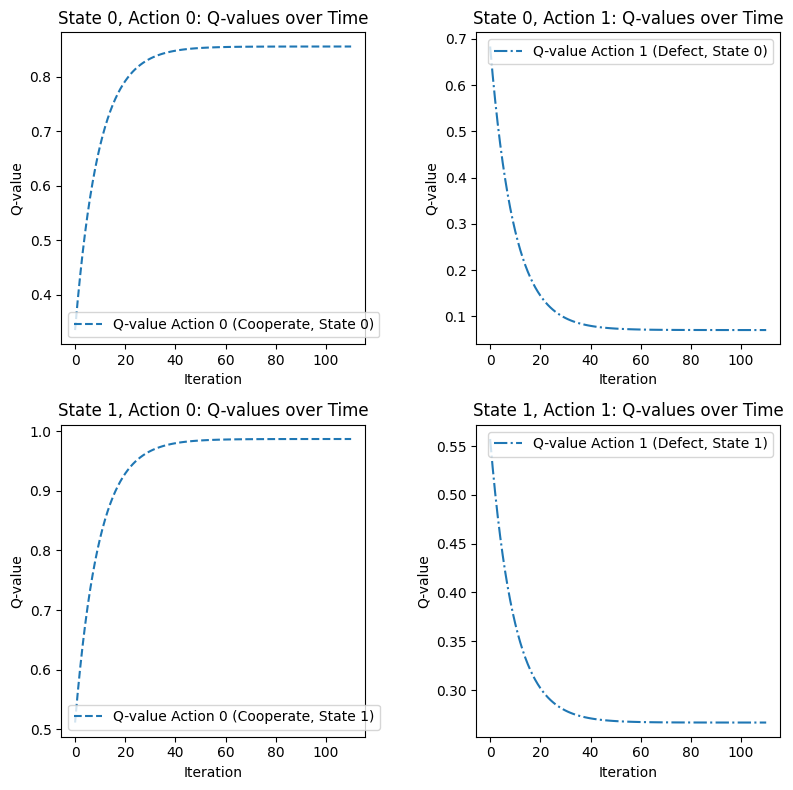

Cooperations: 21, Defections: 1067


In [11]:
# Run the solver
cooperations, defections, q1_history_per_sample, mean_q_values, grim_trigger_count_dict, initial_q_value = solver.run()
# Check results
print(f"Cooperations: {cooperations}, Defections: {defections}")


### Calculate Theoretical Q-Values

In [7]:
calculator = Theoretical_QValueCalculator(epsilon=epsilon_value, P=P, R=R, T=T, S=S, delta=delta_value)
Q00, Q01, Q10, Q11 = calculator.calculate_q_values(c1, c2)


Strategy is e-GrimTrigger


In [8]:
Q00, Q01, Q10, Q11

(1.3001735106998265,
 0.23995373048004623,
 1.1410526315789473,
 0.4210526315789473)

### Value Iteration Check

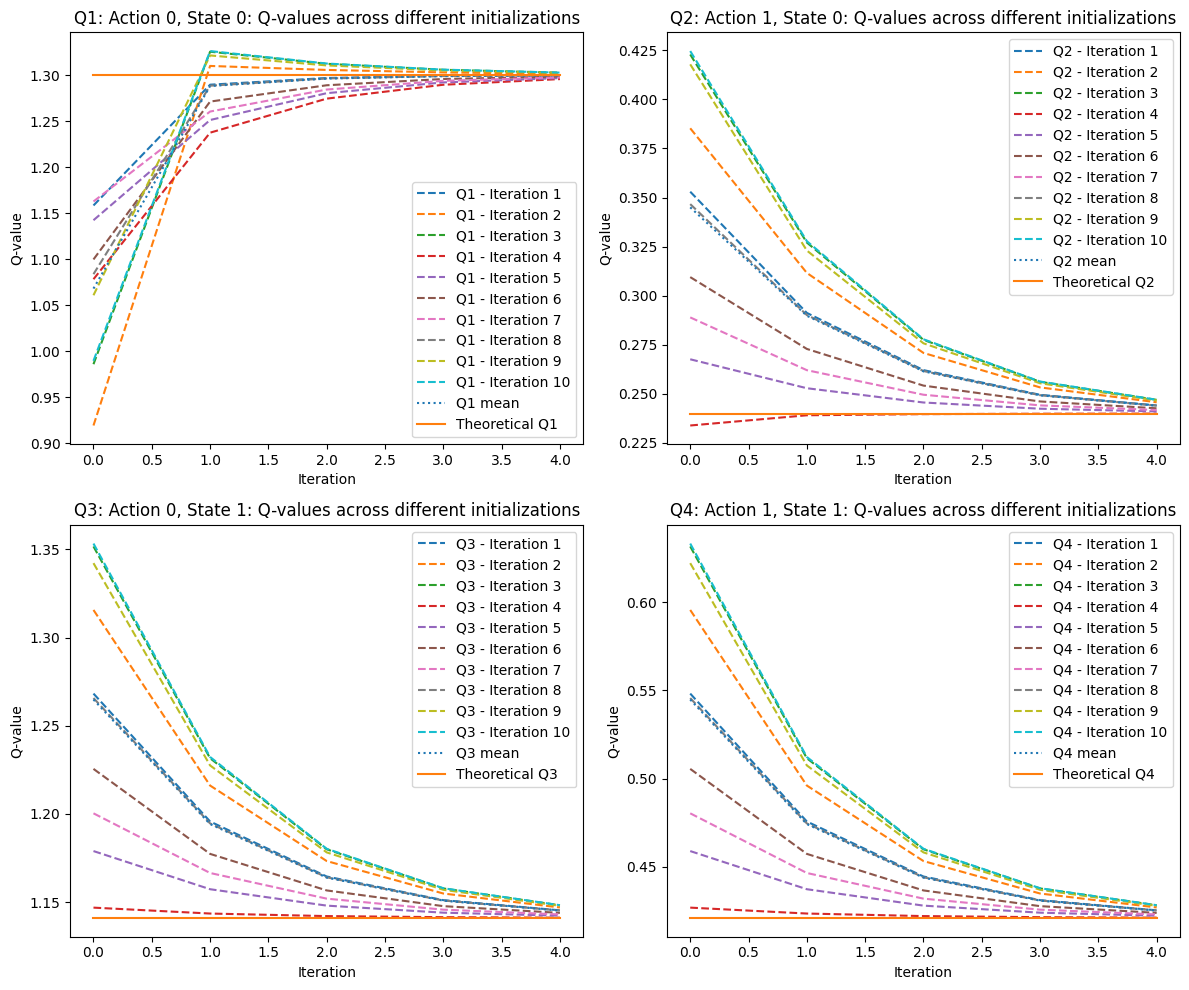

In [9]:
solver.plot_value_iteration(Q00, Q01, Q10, Q11, False)

## Critical Value of delta

In [ ]:
def analyze_critical_delta(delta_values, epsilon_values):
    """
    Analyzes the critical value of delta for which the agent begins cooperating against the Grim Trigger strategy.

    Parameters:
        None.

    Returns:
        A plot of cooperation ratio vs. delta.
    """
    import numpy as np
    import matplotlib.pyplot as plt

    # Define the payoffs
    P, R, T, S = 0.2, 0.8, 1, 0

    # Create a 2D grid for strategies
    strategy_grid = np.zeros((len(delta_values), len(epsilon_values)))

    # Iterate over all (delta, epsilon) pairs
    for i, delta in enumerate(delta_values):
        for j, epsilon in enumerate(epsilon_values):
            if epsilon == 1:  # Avoid division by zero when epsilon is 1
                strategy_grid[i, j] = 0
                continue
            # Example calculation (replace this with actual logic)
            calculator = Theoretical_QValueCalculator(epsilon=epsilon, P=P, R=R, T=T, S=S, delta=delta)
            c1, c2 = calculator.calculate_c1_c2()
            strategy = calculator.print_strategy_chosen(c1, c2)
            strategy_grid[i, j] = strategy

    # Debug: Ensure all values are in the expected range
    strategy_grid = np.clip(strategy_grid, 1, 4)  # Clip values to ensure they are in [1, 4]
    return strategy_grid

def plot_strategy_grid(strategy_grid, delta_values, epsilon_values):
    """
    Plots the strategy grid with clear color mapping.

    Parameters:
        strategy_grid (np.ndarray): 2D array representing the strategies.
        delta_values (np.ndarray): Array of delta values.
        epsilon_values (np.ndarray): Array of epsilon values.

    Returns:
        None. Displays the plot.
    """
    import numpy as np
    import matplotlib.pyplot as plt

    # Debug: Print unique values in the strategy grid
    unique_strategies = np.unique(strategy_grid)
    print("Unique strategies in grid:", unique_strategies)

    # Define the color mapping
    levels = [0, 1, 2, 3, 4]  # Define boundaries for strategies
    colors = ['white', 'blue', 'orange', 'green', 'white']  # Color for each strategy
    cmap = plt.matplotlib.colors.ListedColormap(colors[1:])  # Omit 'white' as it's for level 0

    # Create the mesh grid
    delta_mesh, epsilon_mesh = np.meshgrid(epsilon_values, delta_values)

    # Plotting
    plt.figure(figsize=(13, 10))
    contour = plt.contourf(delta_mesh, epsilon_mesh, strategy_grid, levels=levels, cmap=cmap, extend='both')

    # Add color bar with proper ticks and labels
    cbar = plt.colorbar(contour, ticks=[1, 2, 3])  # Adjusted ticks to match the strategy levels
    cbar.set_label('Strategy')
    cbar.ax.set_yticklabels(['AD', 'GT', 'AC'])

    # Label axes and title
    plt.xlabel(r'$\epsilon$')
    plt.ylabel(r'$\delta$')
    plt.title('Strategy Choice Based on $\delta$ and $\epsilon$')

    # Display the plot
    plt.show()


In [ ]:
# Range of delta and epsilon values
delta_values = np.linspace(0, 0.999, 100)
epsilon_values = np.linspace(0, 0.99, 100)
a = analyze_critical_delta(delta_values, epsilon_values)

In [12]:
pd.DataFrame((a).reshape(1,10000).T)[0].value_counts()

0
1.0    6541
2.0    3359
3.0     100
Name: count, dtype: int64

Unique strategies in grid: [1. 2. 3.]


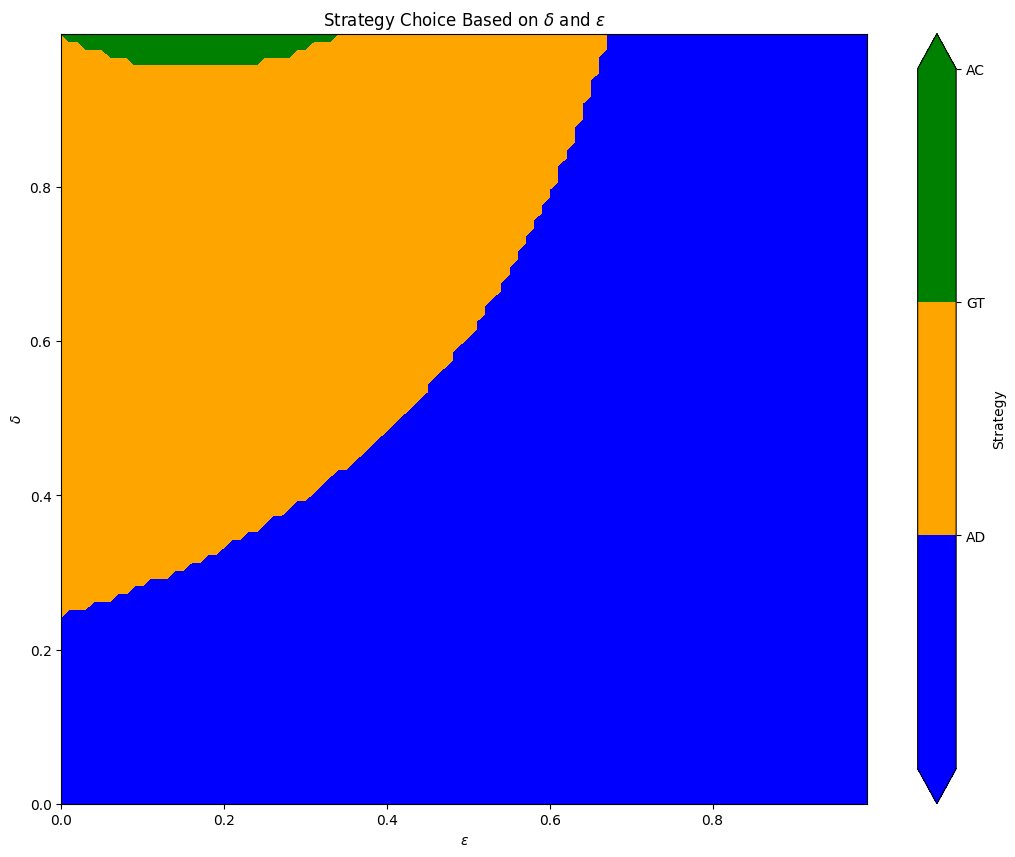

In [14]:
plot_strategy_grid(a, delta_values, epsilon_values)

In [ ]:
#TODO : analyse post based on the last qvalues matrix = after value iteration, which strategy is going to.
#convention in Sutton and let the code match the notation
def analyze_critical_delta_empirically(delta_values, epsilon_values):
    """
    Analyzes the critical value of delta for which the agent begins cooperating against the Grim Trigger strategy.

    Parameters:
        None.

    Returns:
        A plot of cooperation ratio vs. delta.
    """
    import numpy as np
    import matplotlib.pyplot as plt

    # Define the payoffs
    P, R, T, S = 0.2, 0.8, 1, 0

    # Create a 2D grid for strategies
    strategy_grid = np.zeros((len(delta_values), len(epsilon_values)))

    # Iterate over all (delta, epsilon) pairs
    for i, delta in enumerate(delta_values):
        for j, epsilon in enumerate(epsilon_values):
            if epsilon == 1:  # Avoid division by zero when epsilon is 1
                strategy_grid[i, j] = 0
                continue
            
            # Example calculation (replace this with actual logic)
            
            calculator = Theoretical_QValueCalculator(epsilon=epsilon, P=P, R=R, T=T, S=S, delta=delta)
            c1, c2 = calculator.calculate_c1_c2()

            k = 500 #if delta > c2 else 5 

            #Here in the comment,  I was incrementing only for AC because we had noticed that more iterations are needed in this case. 
            #However, it seems that the pairs of epsilon and delta values that lie at the boundaries between strategies still require more iterations. 

           
            strategy = epsilon_GrimTrigger()
            solver = PrisonersDilemmaSolver(
                strategy=strategy,
                e_initial=epsilon,
                lambda_val=0,
                alpha=0.1,
                delta=delta,
                K=k,
                M=1,
                e_decay=1,
                random_uniform=True,
                verbose=False)
            val_inner_value_iteration = solver.check_value_iteration()
            dfs = convert_dict_to_mean_df(val_inner_value_iteration, mean=False)
            b = dfs[0][-1:]
            GT = np.any((b['Q1'] > b['Q3']) & (b['Q2'] < b['Q4']))
            AD = np.any((b['Q1'] < b['Q3']) & (b['Q2'] < b['Q4']))
            AC = np.any((b['Q1'] > b['Q3']) & (b['Q2'] > b['Q4']))
            
            if AD:
                strategy_grid[i, j] =  1  # e-Always Defecting
            elif GT:
                strategy_grid[i, j] =  2  # e-GrimTrigger
            elif AC:
                strategy_grid[i, j] = 3

            else:
                print('for delta value {delta} and epsilon value {epsilon} the value iteration is not converging correctly to a predefined strategy')
                strategy_grid[i, j] = 4

    # Debug: Ensure all values are in the expected range
    strategy_grid = np.clip(strategy_grid, 1, 4)  # Clip values to ensure they are in [1, 4]
    return strategy_grid



In [77]:
# Range of delta and epsilon values
delta_values = np.linspace(0, 0.999, 1000)
epsilon_values = np.linspace(0, 0.99, 1000)
a = analyze_critical_delta_empirically(delta_values, epsilon_values)

Unique strategies in grid: [1. 2. 3.]


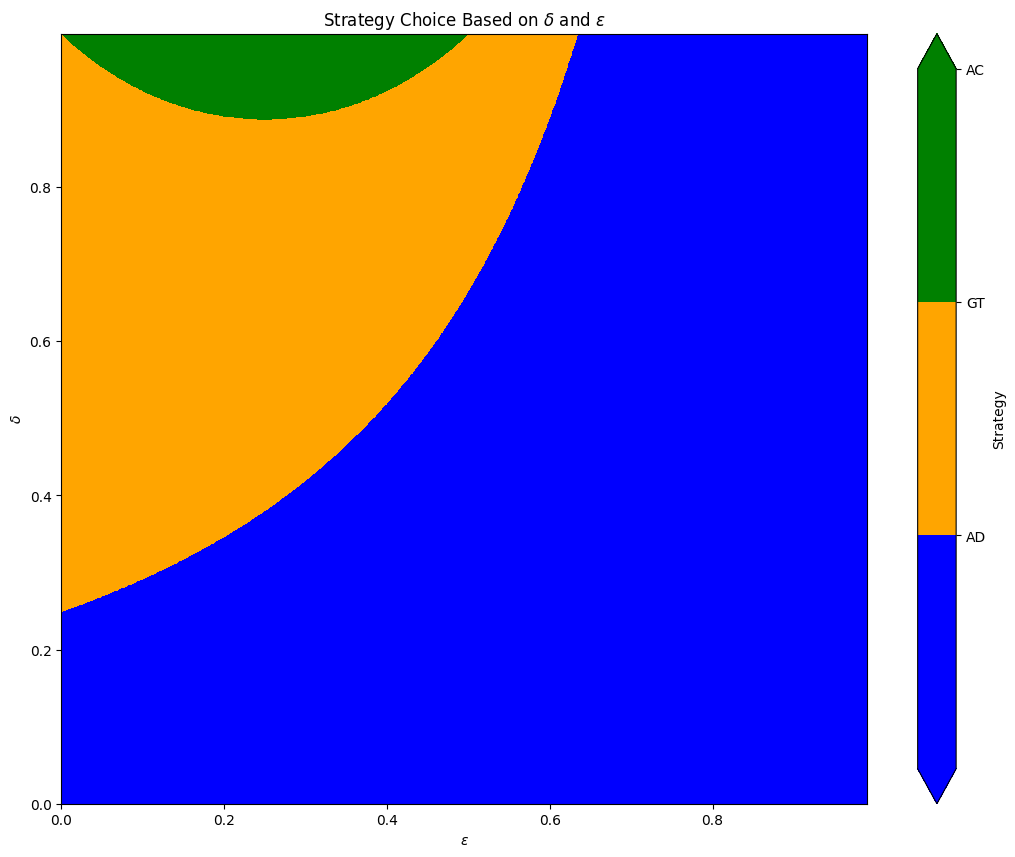

In [78]:
plot_strategy_grid(a, delta_values, epsilon_values)

## Alpha Plot

In [15]:
dfs = convert_dict_to_mean_df(q1_history_per_sample, mean=False)

In [23]:
def plot_alpha(dfs, theoretical_q_values, title = 'Q1'):
    """
    Plots the value iteration process, including Q-values convergence and starting points.

    Parameters:
    - q1_history: List of Q-value matrices over iterations.
    - theoretical_q_values: Target theoretical Q-values to compare.
    - alpha: The scaling factor affecting the starting points.
    - title: Title of the plot (default: "Alpha Plot").
    """

    # Define a colormap or list of colors
    colors = plt.cm.tab10(np.linspace(0, 1, len(dfs)))

    plt.figure(figsize=(10, 6))

    for i in range(len(dfs)):
        q1_history = dfs[i][title]
        # Extract maximum Q-value per iteration
        iterations = len(q1_history)
        max_q_values = [np.max(q) for q in q1_history]

        # Starting points based on max Q-values
        starting_points = [max_q_values[i] for i in range(iterations)]

        # Plot max Q-values with different colors
        plt.plot(max_q_values, label=f"sample #{i}", 
                marker="o", color=colors[i], linewidth=2, alpha=0.7)

        # Add starting points with distinct style
        for j, start in enumerate(starting_points):
            plt.scatter(j, start, color=colors[i], s=60, marker="o", alpha=0.5)

    # Add the theoretical Q-values line
    plt.axhline(np.max(theoretical_q_values), color="red", linestyle="--", label="Theoretical Q-values")

    # Add labels, legend, and grid
    plt.xlabel("Alpha steps", fontsize=12)
    plt.ylabel("Q-values", fontsize=12)
    plt.title(title, fontsize=14)
    plt.legend(fontsize=10, loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.xlim(0, 50)
    # Show the combined plot
    plt.show()



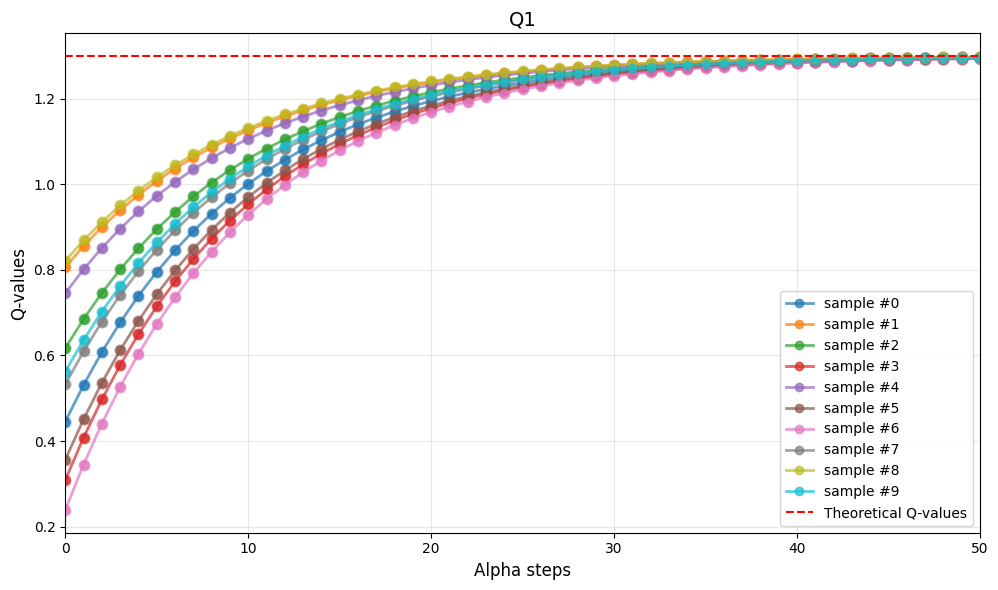

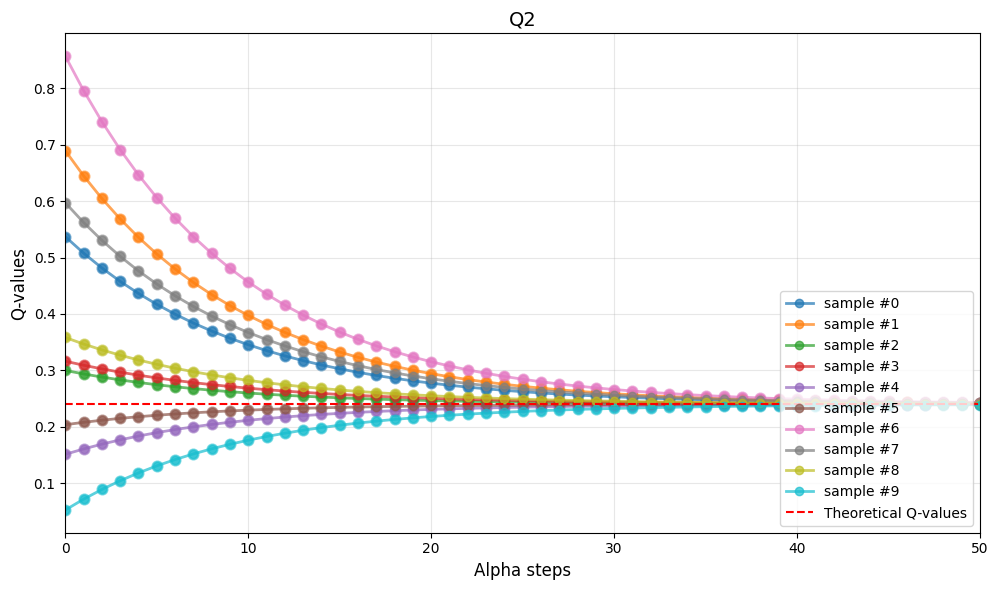

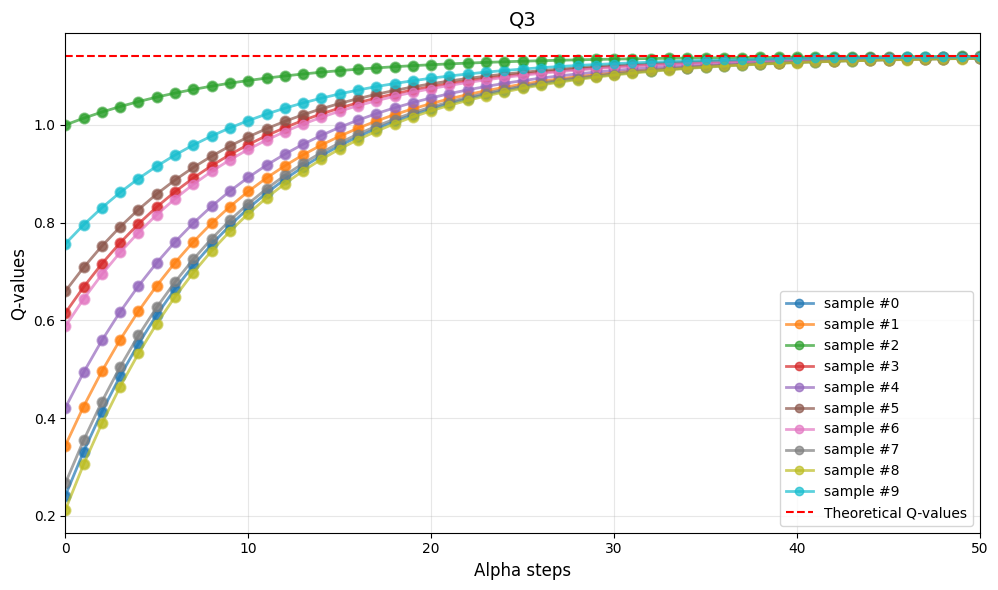

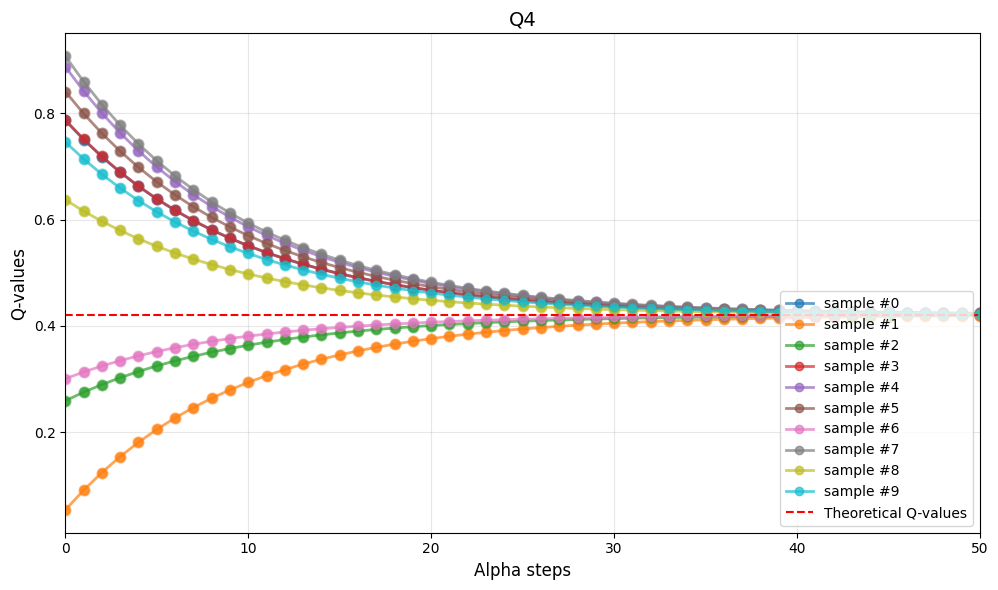

In [24]:
plot_alpha(dfs, Q00, title='Q1')
plot_alpha(dfs, Q01, title = 'Q2')
plot_alpha(dfs, Q10, title = 'Q3')
plot_alpha(dfs, Q11, title = 'Q4')

In [ ]:
#write on latex on the plot title and x-y axis